In [16]:
import tensorflow as tf

In [ ]:
train = tf.keras.utils.image_dataset_from_directory(
    "../data/classification/Train",
    image_size=(224, 224),
    batch_size=32,
    shuffle=True
)

val = tf.keras.utils.image_dataset_from_directory(
    "../data/classification/Val",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

test = tf.keras.utils.image_dataset_from_directory(
    "../data/classification/Test",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

Found 4218 files belonging to 4 classes.
Found 787 files belonging to 4 classes.
Found 789 files belonging to 4 classes.


In [18]:
def preprocess(images, labels):
    images = tf.cast(images, tf.float32)
    images = images / 127.5 - 1
    return images, labels

train = train.map(preprocess)
val = val.map(preprocess)
test = test.map(preprocess)

In [ ]:

# 1. Configurer Keras avant les imports
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import tensorflow_hub as hub
import tf_keras as keras



url = "https://tfhub.dev/google/imagenet/inception_v1/feature_vector/4"

base_model = hub.KerasLayer(
    url,
    trainable=False,
    name="inceptionv1"
)

model = keras.Sequential([
    keras.layers.Input(shape=(224, 224, 3)),
    base_model,
    keras.layers.Dropout(0.4),
    keras.layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 inceptionv1 (KerasLayer)    (None, 1024)              5607184   
                                                                 
 dropout (Dropout)           (None, 1024)              0         
                                                                 
 dense_3 (Dense)             (None, 4)                 4100      
                                                                 
Total params: 5611284 (21.41 MB)
Trainable params: 4100 (16.02 KB)
Non-trainable params: 5607184 (21.39 MB)
_________________________________________________________________


In [24]:

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train,
    validation_data=val,
    epochs=15,
    callbacks=[early_stopping]
)


Epoch 1/15
132/132 [==============================] - 11s 61ms/step - loss: 1.0500 - accuracy: 0.5458 - val_loss: 0.8046 - val_accuracy: 0.7319
Epoch 2/15
132/132 [==============================] - 8s 58ms/step - loss: 0.7753 - accuracy: 0.6904 - val_loss: 0.7103 - val_accuracy: 0.7560
Epoch 3/15
132/132 [==============================] - 8s 58ms/step - loss: 0.6944 - accuracy: 0.7274 - val_loss: 0.6568 - val_accuracy: 0.7586
Epoch 4/15
132/132 [==============================] - 8s 58ms/step - loss: 0.6388 - accuracy: 0.7504 - val_loss: 0.5966 - val_accuracy: 0.7878
Epoch 5/15
132/132 [==============================] - 8s 58ms/step - loss: 0.5953 - accuracy: 0.7743 - val_loss: 0.5765 - val_accuracy: 0.8094
Epoch 6/15
132/132 [==============================] - 8s 58ms/step - loss: 0.5629 - accuracy: 0.7862 - val_loss: 0.5624 - val_accuracy: 0.7929
Epoch 7/15
132/132 [==============================] - 8s 58ms/step - loss: 0.5435 - accuracy: 0.7873 - val_loss: 0.5375 - val_accuracy: 0.806

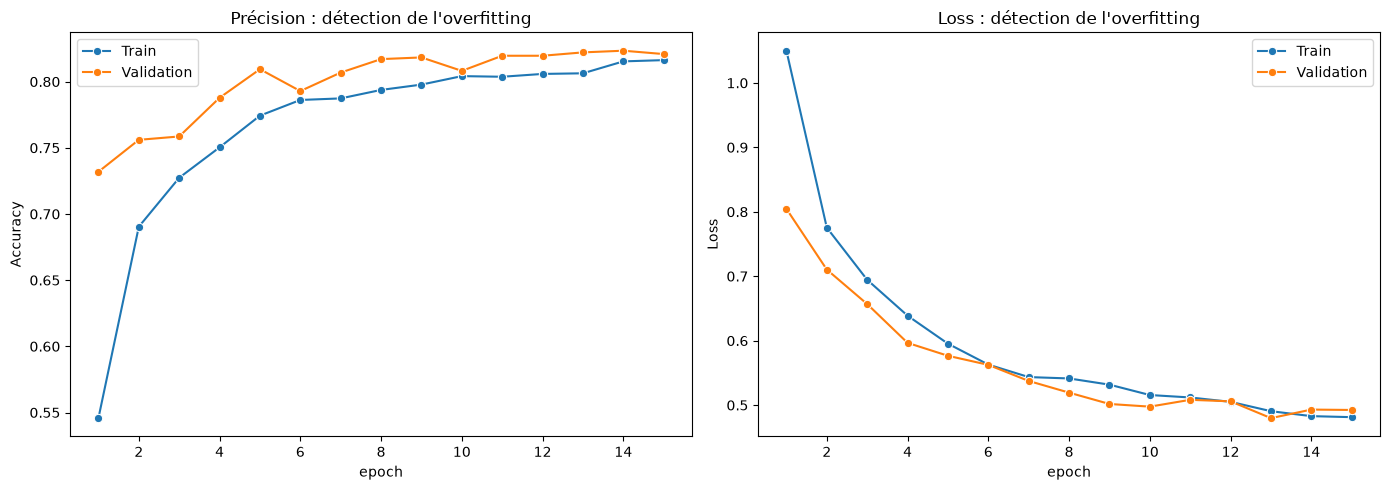

In [25]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame(history.history)

df["epoch"] = range(1, len(df) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(data=df, x="epoch", y="accuracy",
             marker="o", label="Train", ax=axes[0])

sns.lineplot(data=df, x="epoch", y="val_accuracy",
             marker="o", label="Validation", ax=axes[0])

axes[0].set_title("Précision : détection de l'overfitting")
axes[0].set_ylabel("Accuracy")

sns.lineplot(data=df, x="epoch", y="loss",
             marker="o", label="Train", ax=axes[1])

sns.lineplot(data=df, x="epoch", y="val_loss",
             marker="o", label="Validation", ax=axes[1])

axes[1].set_title("Loss : détection de l'overfitting")
axes[1].set_ylabel("Loss")

plt.tight_layout()
plt.show()


In [13]:
train,test,val

(<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>,
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>,
 <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>)